In [ ]:
import marimo as mo

# ordering (sort_by_synteny)

## setup

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path
from matplotlib.colors import to_rgba

In [ ]:
def main_ribbon_painter(top_chr_span, bot_chr_span, y_top, y_bot, rgba):
    xa1, xa2 = top_chr_span
    xb1, xb2 = bot_chr_span
    y_mid = (y_top + y_bot) / 2.0
    verts = [(xa1, y_top), (xa1, y_mid), (xb1, y_mid), (xb1, y_bot), (xb2, y_bot), (xb2, y_mid), (xa2, y_mid), (xa2, y_top), (xa1, y_top)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), facecolor=rgba, edgecolor="none", linewidth=0)

def foot(cx):
    return (cx - 0.03, cx + 0.03)

In [ ]:
TOP, BOT, H = 1.0, 0.0, 0.12
color = {"A1": "red", "A2": "blue", "A3": "green"}

def x_of(order, name):
    return (order.index(name) + 1) / (len(order) + 1)

def draw(top, bottom, links):
    fig, ax = plt.subplots(figsize=(6, 2.6))
    for name in top:
        ax.add_patch(Rectangle((x_of(top, name) - 0.08, TOP), 0.16, H, facecolor=color[name]))
        ax.text(x_of(top, name), TOP + 0.22, name, ha="center", fontsize=10)
    for name in bottom:
        ax.add_patch(Rectangle((x_of(bottom, name) - 0.08, BOT), 0.16, H, facecolor="gray"))
        ax.text(x_of(bottom, name), BOT - 0.18, name, ha="center", fontsize=10)
    for cu, cl in links:
        ax.add_patch(main_ribbon_painter(foot(x_of(top, cu)), foot(x_of(bottom, cl)), TOP, BOT + H, to_rgba(color[cu], 0.6)))
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.35, 1.45)
    ax.axis("off")
    return fig

## 1 one link

ok as before just draw the link, for simplicity here function will be called 'draw()'

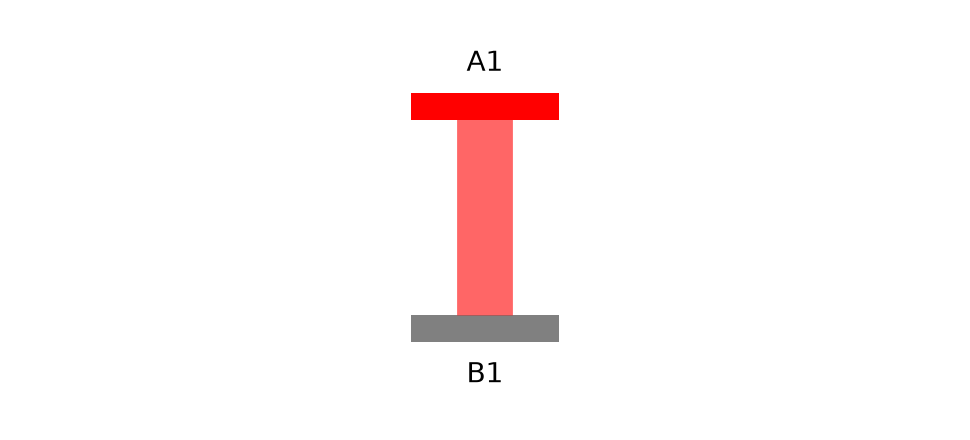

In [ ]:
draw(["A1"], ["B1"], [("A1", "B1")])

## 2 Chr

Now lets add Chromosomes, but no OGs yet.

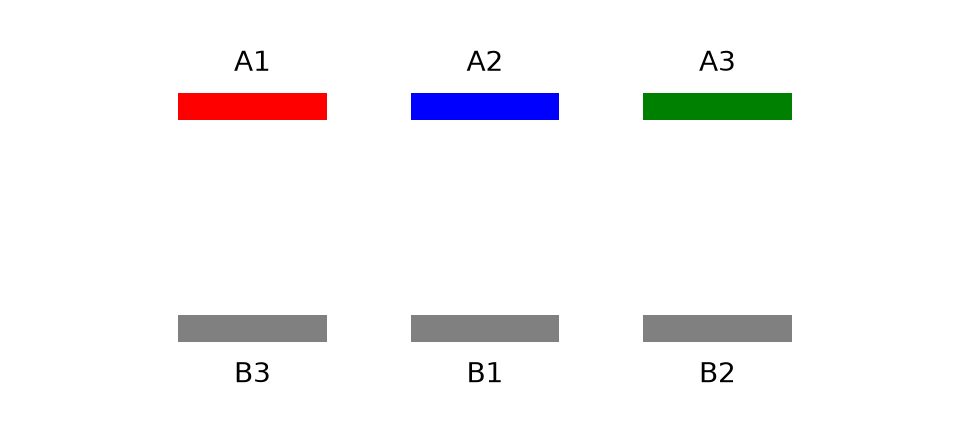

In [ ]:
top = ["A1", "A2", "A3"]
bottom = ["B3", "B1", "B2"]

draw(top, bottom, [])

## 3 Orthologs / links

Now we add orthologs. Lets not mess with coordinates too much and they'll just hit their orthologous Chr.

In [ ]:
clean_links = [
    ("A1", "B1"),
    ("A1", "B1"),
    ("A1", "B1"),
    ("A2", "B2"),
    ("A2", "B2"),
    ("A3", "B3"),
    ("A3", "B3"),
    ("A3", "B3"),
]

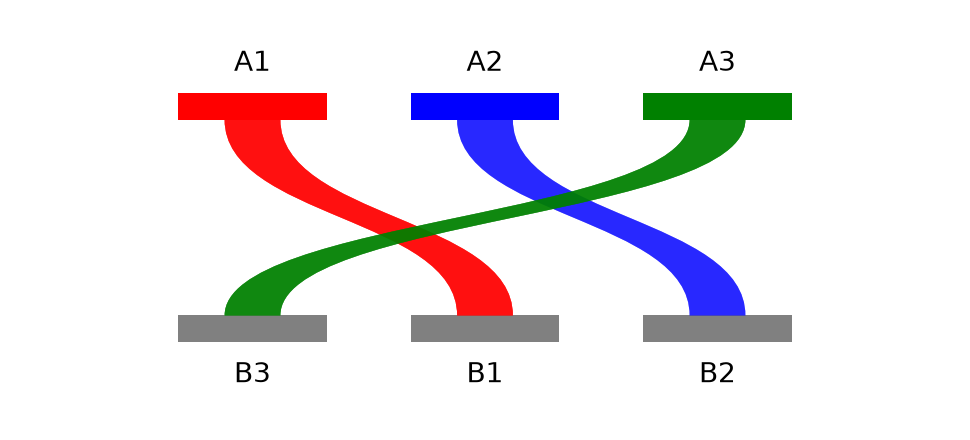

In [ ]:
draw(top, bottom, clean_links)

## 4 real data
to make it even a bit more complicated there are some cases where there is a paralog on different chr.

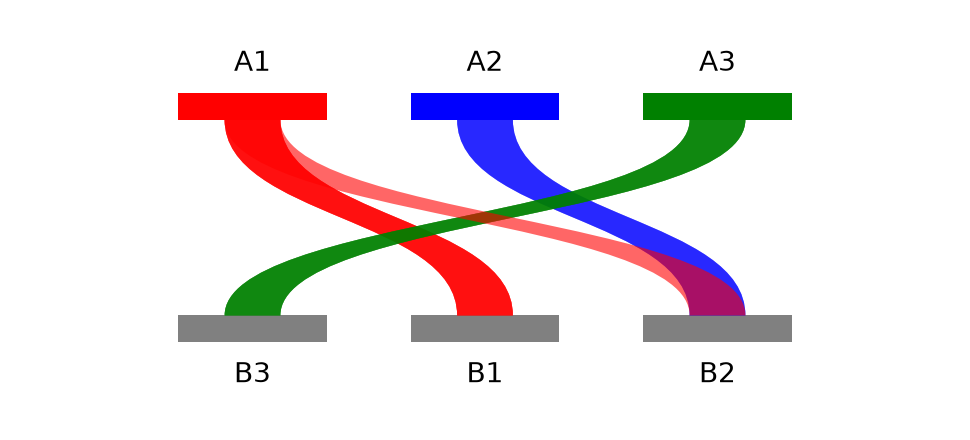

In [ ]:
links = clean_links + [("A1", "B2")]

draw(top, bottom, links)

## 5 number the top row

Top row never moves, only bottom one is being sorted. So we just give every top Chr a number by its position: A1 is 0, A2 is 1, A3 is 2 (python counts from 0, not from 1).

Why we need it: later we want to put every bottom Chr under its partner. But "under A2" is not a thing computer can sort by, `1` is. So this dict is just translation from Chr name to its place on top.

In [ ]:
upper_rank = {}                   # empty dict, we fill it below
for rank, chrom in enumerate(top): # enumerate gives 0 with "A1", then 1 with "A2", then 2 with "A3"
    upper_rank[chrom] = rank     # so we write it down as A1 -> 0, A2 -> 1, A3 -> 2

upper_rank                 # prints it

## 6 count the links of every bottom chromosome

For every bottom Chr we count how many links it has to each top Chr. Output is a dict inside a dict, like `{"B2": {"A2": 2, "A1": 1}}`, which just means "B2 has 2 links to A2 and 1 link to A1".

`cu` and `cl` are short for chromosome upper and chromosome lower, thats how they are called in functions.py.

`.get(cu, 0)` is a small trick: it asks the dict "how many links to this top Chr so far?" and if we never seen this pair before it answers 0 instead of crashing. Then we add 1.

In [ ]:
def links_to_upper(order_lower, upper_rank, links):
    links_to = {}                   # here we collect all the counts
    for chrom in order_lower:
        links_to[chrom] = {}         # every bottom Chr gets its own empty box: B3, B1, B2
    for cu, cl in links:              # cu is top Chr of that link, cl is bottom one
        if cl in links_to and cu in upper_rank:              # skip links to Chr we dont draw
            links_to[cl][cu] = links_to[cl].get(cu, 0) + 1   # +1 to the counter of this exact pair
    return links_to

links_to = links_to_upper(bottom, upper_rank, links)
links_to                              # prints it

## 7 B2 has two partners, so we have to choose

B2 is the interesting one bc of that paralog we added in step 4, so it has two links/OGs. We cant put B2 under both, so we have to pick one.

In [ ]:
links_to["B2"]                        # B2 box only, to see the problem

## 8 the sort key: where its strongest partner sits

For every bottom Chr this makes two numbers, and those numbers is what we sort by later.

First number is position of its best partner, so B2 gets 1 bc its best partner A2 stands on place 1. Thats the one doing all the work.

Second number is the count but with minus. Minus bc sorting goes from small to big, and if two bottom Chr have the same best partner we want the one with MORE links to come first. -3 is smaller than -2, so more links wins.

`max(partners, key=partners.get)` means "give me the key with biggest value". Without `key=` python would compare the names like words and give A2 just bc its later in alphabet, which is nonsense.

Last line is for a Chr with no links at all. `len(upper_rank)` is 3 here, and real positions are only 0,1,2, so 3 is always bigger and such Chr lands at the very end.

In [ ]:
def synteny_sort_key(partners, upper_rank):
    if partners:    # if this Chr has any links at all
        best = max(partners, key=partners.get)     # name of the partner with most links
        return (upper_rank[best], -partners[best])  # (where that partner stands, minus how many links)
    return (len(upper_rank), 0) # no links -> big number -> goes to the end

synteny_sort_key(links_to["B2"], upper_rank) 

## 9 sort the bottom row by that key

Now we just make a list where every bottom Chr carries its key, and let it be sorted.

Python sorts tuples by first element, and only if its a miss-match it looks at second thing, then third. So `old_index` in the middle is a tiebreaker: if two Chr somehow get exactly same key, they stay in the order they came in and dont jump around randomly.

Then last loop just throws away keys and indexes and keeps only names, bc thats all we need for drawing.

In [ ]:
ranked_chromosomes = []
for old_index, chrom_2 in enumerate(bottom):    # old_index is where it was before sorting
    ranked_chromosomes.append((synteny_sort_key(links_to[chrom_2], upper_rank), old_index, chrom_2))

ranked_chromosomes.sort()   # python does the actual sorting here

new_order = []
for sort_key, old_index_2, chrom_3 in ranked_chromosomes:
    new_order.append(chrom_3)   # keep only the names, drop the rest

new_order

## 10 drawn in the sorted order

Same links, same top row, only bottom list is different now. And this time its not being moved manualy but with `new_order` from step 9.

The red ribbon going to B2 is still crossing and thats correct, its that paralog. Sorting makes less crossings, it cant make zero of them if data itself is messy.

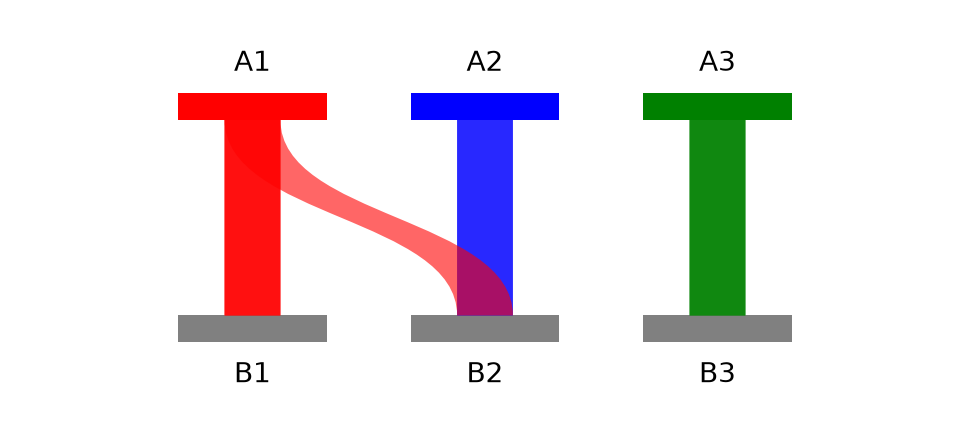

In [ ]:
draw(top, new_order, links)   # new_order, not bottom

## 11 this is sort_by_synteny

Thats basically it, `sort_by_synteny` in functions.py does exactly those steps, `links_to_upper` and `synteny_sort_key` are even same functions (there they are with `_` in front bc they are used only inside).

Whats different there:

- it does it for every pair of species down the chain, not just two rows. First species stays as it is, second gets sorted under first, third under second and so on.
- links come from a dataframe not from list of tuples, so it reads `df["chr1"]` and `df["chr2"]` instead of my tuples.
- there is second mode called "center" which puts Chr not under its best partner but in the average of all its partners. Sometimes gives less crossings when one Chr is split into many.